Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Create Sales Dataset

In [ ]:
data = {
    'Order_ID': [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    'Product_Category': [
        'Electronics', 'Clothing', 'Grocery', 'Furniture', 'Books',
        'Sports', 'Electronics', 'Clothing', 'Grocery', 'Furniture'
    ],
    'Quantity': [2, 3, 5, 1, 4, 2, 1, 5, 3, 2],
    'Price': [50000, 1500, 200, 12000, 500, 3000, 25000, 2000, 300, 15000]
}

df = pd.DataFrame(data)

print(df)

   Order_ID Product_Category  Quantity  Price
0       101      Electronics         2  50000
1       102         Clothing         3   1500
2       103          Grocery         5    200
3       104        Furniture         1  12000
4       105            Books         4    500
5       106           Sports         2   3000
6       107      Electronics         1  25000
7       108         Clothing         5   2000
8       109          Grocery         3    300
9       110        Furniture         2  15000


Save data in CSV, Excel and JSON

In [ ]:
df.to_csv('Sales_Data.csv', index=False)
df.to_excel('Sales_Data.xlsx', index=False)
df.to_json('Sales_Data.json', orient='records')

print("Files created successfully")

Files created successfully


Load all three formats

In [ ]:
csv_data = pd.read_csv('Sales_Data.csv')
excel_data = pd.read_excel('Sales_Data.xlsx')
json_data = pd.read_json('Sales_Data.json')

print("CSV:")
print(csv_data.head())

print("\nExcel:")
print(excel_data.head())

print("\nJSON:")
print(json_data.head())

CSV:
   Order_ID Product_Category  Quantity  Price
0       101      Electronics         2  50000
1       102         Clothing         3   1500
2       103          Grocery         5    200
3       104        Furniture         1  12000
4       105            Books         4    500

Excel:
   Order_ID Product_Category  Quantity  Price
0       101      Electronics         2  50000
1       102         Clothing         3   1500
2       103          Grocery         5    200
3       104        Furniture         1  12000
4       105            Books         4    500

JSON:
   Order_ID Product_Category  Quantity  Price
0       101      Electronics         2  50000
1       102         Clothing         3   1500
2       103          Grocery         5    200
3       104        Furniture         1  12000
4       105            Books         4    500


Explore the data

In [ ]:
print("Shape:", df.shape)
print("Columns:", df.columns)
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())


Shape: (10, 4)
Columns: Index(['Order_ID', 'Product_Category', 'Quantity', 'Price'], dtype='object')

Data Types:
Order_ID             int64
Product_Category    object
Quantity             int64
Price                int64
dtype: object

Missing Values:
Order_ID            0
Product_Category    0
Quantity            0
Price               0
dtype: int64

Duplicates: 0


Clean the data

In [ ]:
df = df.drop_duplicates()

df['Product_Category'] = df['Product_Category'].str.strip().str.title()

print("Data cleaned successfully")
print(df)

Data cleaned successfully
   Order_ID Product_Category  Quantity  Price
0       101      Electronics         2  50000
1       102         Clothing         3   1500
2       103          Grocery         5    200
3       104        Furniture         1  12000
4       105            Books         4    500
5       106           Sports         2   3000
6       107      Electronics         1  25000
7       108         Clothing         5   2000
8       109          Grocery         3    300
9       110        Furniture         2  15000


Convert to common DataFrame

In [ ]:
common_df = pd.concat([csv_data, excel_data, json_data])

common_df = common_df.drop_duplicates()

print(common_df)

   Order_ID Product_Category  Quantity  Price
0       101      Electronics         2  50000
1       102         Clothing         3   1500
2       103          Grocery         5    200
3       104        Furniture         1  12000
4       105            Books         4    500
5       106           Sports         2   3000
6       107      Electronics         1  25000
7       108         Clothing         5   2000
8       109          Grocery         3    300
9       110        Furniture         2  15000


Data Transformation

In [ ]:
df['Total_Sales'] = df['Quantity'] * df['Price']

print(df)

   Order_ID Product_Category  Quantity  Price  Total_Sales
0       101      Electronics         2  50000       100000
1       102         Clothing         3   1500         4500
2       103          Grocery         5    200         1000
3       104        Furniture         1  12000        12000
4       105            Books         4    500         2000
5       106           Sports         2   3000         6000
6       107      Electronics         1  25000        25000
7       108         Clothing         5   2000        10000
8       109          Grocery         3    300          900
9       110        Furniture         2  15000        30000


Descriptive Statistics

In [ ]:
print(df.describe())

        Order_ID  Quantity         Price    Total_Sales
count   10.00000  10.00000     10.000000      10.000000
mean   105.50000   2.80000  10950.000000   19140.000000
std      3.02765   1.47573  16022.917615   30125.043107
min    101.00000   1.00000    200.000000     900.000000
25%    103.25000   2.00000    750.000000    2625.000000
50%    105.50000   2.50000   2500.000000    8000.000000
75%    107.75000   3.75000  14250.000000   21750.000000
max    110.00000   5.00000  50000.000000  100000.000000


Sales Analysis

In [ ]:
print("Total Sales:", df['Total_Sales'].sum())

print("Average Order Value:", df['Total_Sales'].mean())

print("\nCategory Distribution:")
print(df['Product_Category'].value_counts())

Total Sales: 191400
Average Order Value: 19140.0

Category Distribution:
Product_Category
Electronics    2
Clothing       2
Grocery        2
Furniture      2
Books          1
Sports         1
Name: count, dtype: int64


Visualizations

Bar Plot: Sales by Product Category

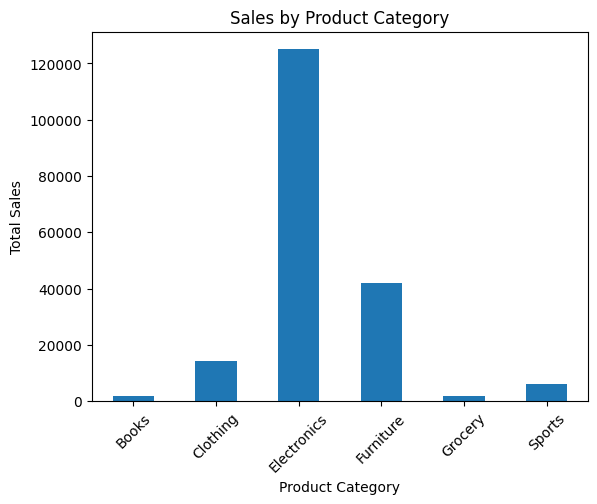

In [ ]:
category_sales = df.groupby('Product_Category')['Total_Sales'].sum()

category_sales.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

Pie Chart: Product Category Distribution

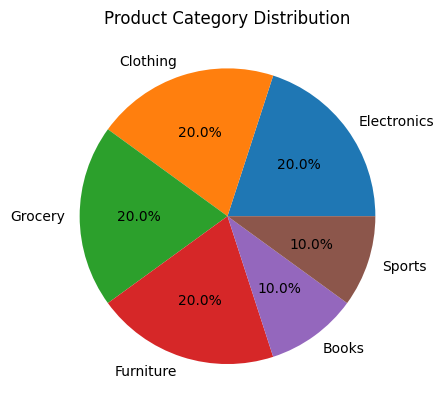

In [ ]:
category_count = df['Product_Category'].value_counts()

plt.pie(category_count, labels=category_count.index, autopct='%1.1f%%')

plt.title('Product Category Distribution')
plt.show()

Box Plot: Total Sales

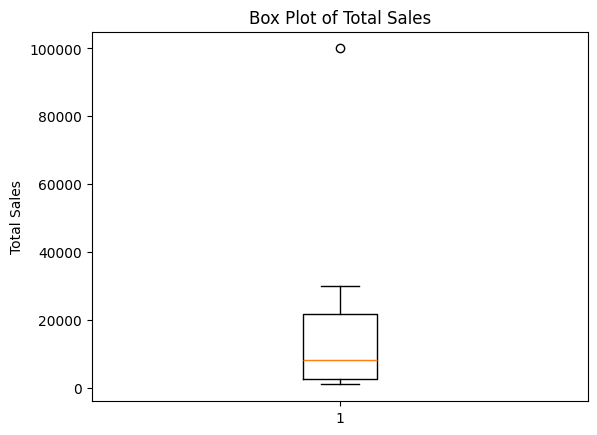

In [ ]:
plt.boxplot(df['Total_Sales'])

plt.title('Box Plot of Total Sales')
plt.ylabel('Total Sales')
plt.show()